# Nivell 1

## Ex1 Niv1 Preguntes analítiques directes (sense integracions complexes)

- We needed to install the mysql connector 


In [143]:
# %pip install mysql-connector-python

📦 Imported Libraries and Their Purpose

To carry out data extraction, cleaning, analysis, and visualization, the following libraries have been imported and grouped by their specific function:

1. Data Analysis & Manipulation
* **`pandas` (`pd`)**: Core library used to structure data into tables (*DataFrames*), perform table joins (`merge`), group data (`groupby`), and calculate summary statistics.

2. Data Visualization
* **`matplotlib.pyplot` (`plt`)**: Foundational plotting library used to create, customize, and configure figure sizes, titles, and axes.
* **`seaborn` (`sns`)**: Built on top of Matplotlib, it simplifies the creation of clean, advanced statistical charts (such as *boxplots* or *line plots*) to analyze data dispersion.

3. Database Connection & Security
* **`mysql.connector`**: Official MySQL driver that connects Python directly to the database to extract tables using SQL queries.
* **`getpass`**: Allows secure password prompts via keyboard input without displaying characters on screen or hardcoding credentials in the script.


- Also need to install sqlalchemy in order to manage sql connections.

In [144]:
# %pip install sqlalchemy pymysql

In [145]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import mysql.connector
from getpass import getpass



In [146]:

connection = mysql.connector.connect(
host="localhost",
port=3306,
user="root",
# password=getpass("Password: "),
password="psw12345$",
# database="transactions"
database="sprint2db"
)

print("Connection working?:", connection.is_connected())

Connection working?: True


### Ex1.1  Com evoluciona el nombre de transaccions al llarg del temps? Exemple de passos guiats amb pandas.

Preguntes analítiques: (només utilitzant la taula de transaccions) :

In [147]:
df_tr = pd.read_sql("SELECT * FROM transaction", connection)

C:\Users\eduar\AppData\Local\Temp\ipykernel_4880\4193330721.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_tr = pd.read_sql("SELECT * FROM transaction", connection)


    Selecciona la columna temporal adequada.
- Columna timestamp (datetime Dtype)

Preguntes analítiques: (només utilitzant la taula de transaccions) :

In [148]:
df_tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                99999 non-null  object        
 1   card_id           99999 non-null  object        
 2   business_id       99999 non-null  object        
 3   timestamp         99999 non-null  datetime64[ns]
 4   amount            99999 non-null  float64       
 5   declined          99999 non-null  int64         
 6   product_ids       99999 non-null  object        
 7   user_id           99999 non-null  object        
 8   lat               99999 non-null  float64       
 9   longitude         99999 non-null  float64       
 10  discount_amount   99999 non-null  float64       
 11  tax_amount        99999 non-null  float64       
 12  shipping_amount   99999 non-null  float64       
 13  channel           99999 non-null  object        
 14  campaign_id       9999

    Defineix el nivell temporal d'anàlisi.

We will do a yearly analysis

In [149]:
df_tr['year'] = df_tr['timestamp'].dt.year
df_tr["year"].value_counts()

# df_tr['month'] = df_tr['timestamp'].dt.to_period("M")
# df_tr["month"]

year
2021    10298
2022    10106
2020    10093
2019    10015
2023     9985
2024     9951
2017     9915
2018     9912
2015     9870
2016     9854
Name: count, dtype: int64

In [150]:
df_tr['year'] = df_tr['timestamp'].dt.year
df_tr["year"].value_counts()

# df_tr['month'] = df_tr['timestamp'].dt.to_period("M")
# df_tr["month"]

year
2021    10298
2022    10106
2020    10093
2019    10015
2023     9985
2024     9951
2017     9915
2018     9912
2015     9870
2016     9854
Name: count, dtype: int64

- Checking any possible null dates

In [151]:
df_tr["timestamp"].isna().sum()

0

    Compta el nombre de registres per període temporal.

In [152]:
transactions_year = df_tr.groupby('year').size()
# transactions_month = df_tr.groupby('month').size()
transactions_year
# transactions_month

year
2015     9870
2016     9854
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
dtype: int64

    Ordena els resultats cronològicament.

In [153]:
transactions_year

year
2015     9870
2016     9854
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
dtype: int64

    Visualitza l'evolució amb un gràfic de línies amb pandas.

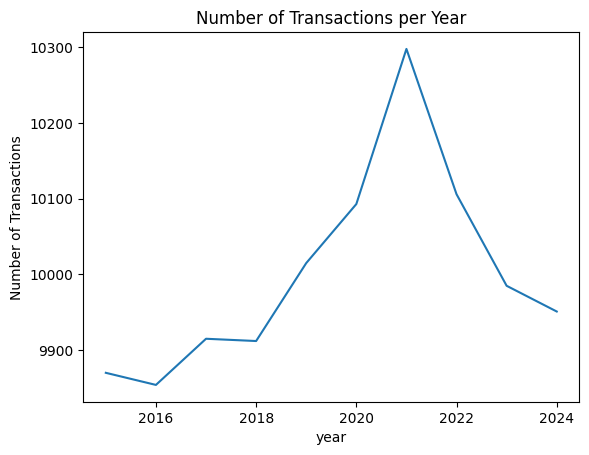

In [154]:
transactions_year.plot(kind='line', x="year", y="amount")

plt.title("Number of Transactions per Year")
plt.ylabel("Number of Transactions");


    versio alternativa IA

> Conclusion: The number of transactions had an increasing tendency that spiked in 2021 but went down equally until 2024

---

### Ex1.2 Niv1. Quins usuaris generen més volum de facturació? Exemple de passos guiats amb seaborn. 



    Identifica la columna que representa el usuari.
- The user is identified in the user_id column.

In [155]:
df_tr.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'year'],
      dtype='object')

    Agrupa les transaccions per usuari i calcula el volum total de facturació sumant la columna amount.


- We create a df_tr_accepted with only the accepted transactions(not declined) 

In [156]:
# df_tr.groupby("user_id")["amount"].sum().reset_index()
df_tr_accepted = df_tr[df_tr["declined"] == 0].copy()

In [157]:
(
df_tr_accepted
.groupby("user_id")["amount"]
.sum()
.reset_index()
);

    Ordena els usuaris de major a menor volum de facturació.


In [158]:
df_tr_accepted.groupby("user_id")["amount"].sum().reset_index().sort_values(by='amount', ascending=False, ignore_index=True)


,user_id,amount
0,289,47332.90
1,318,46393.44
2,455,40594.55
3,417,37393.91
4,185,34560.87
...,...,...
4995,3652,1432.29
4996,1306,1421.15
4997,1995,1405.70
4998,3119,1327.53


    Selecciona els N usuaris principals (per exemple, els 10 primers).
    Representa el resultat mitjançant un gràfic de barres utilitzant Seaborn


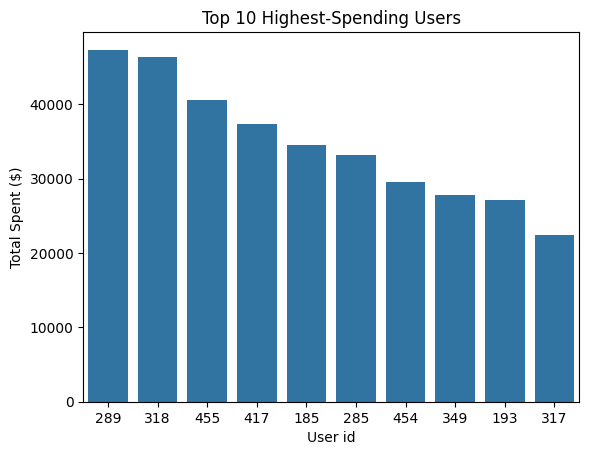

In [159]:
group = (
    df_tr_accepted.groupby("user_id")["amount"]
    .sum()
    .reset_index()
    .sort_values(by='amount', ascending=False, ignore_index=True)
    .head(10)
)

sns.barplot(data=group, x="user_id", y="amount", order=group["user_id"])

plt.title("Top 10 Highest-Spending Users")
plt.xlabel("User id")
plt.ylabel("Total Spent ($)")
plt.show()

    Quins usuaris generen més volum de facturació?
> Based on the bar chart, the users who generate the highest billing volume (amount) are user_id 289 and user_id 318.

Here is the breakdown of the top four users in descending order:
- 289 (highest amount, near $47,000)
- 318 (close second, near $47,000)
- 455 (around $41,000)
- 417 (around $37,500)

---

### Ex1.3. Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades? Exemple de passos guiats amb seaborn.



        Crea una nova columna amb l'hora del dia a partir del timestamp.


In [160]:
df_tr['hour'] = df_tr['timestamp'].dt.hour
# df_tr["hour"]

        Utilitza un violinplot de seaborn per analitzar la distribució dels imports.


All transactions. Declined included.

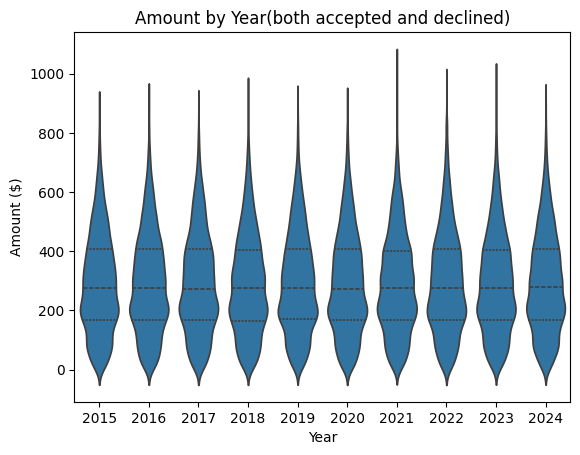

In [161]:
sns.violinplot(x="year", y="amount", data=df_tr, inner="quart")

plt.title("Amount by Year(both accepted and declined)")
plt.xlabel("Year")
plt.ylabel("Amount ($)")
plt.show()


- Only accepted transactions

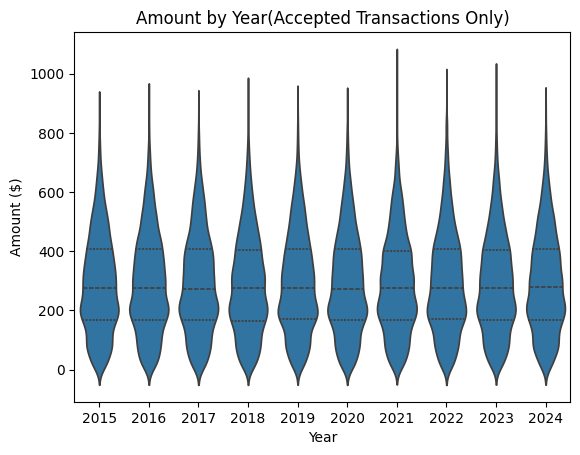

In [162]:
sns.violinplot(x="year", y="amount", data=df_tr_accepted, inner="quart")

plt.title("Amount by Year(Accepted Transactions Only)")
plt.xlabel("Year")
plt.ylabel("Amount ($)")
plt.show()


> The distribution of amount has remained highly stable from 2015 to 2024 indicating consistent customer purchasing behavior across the entire decade.


        Assigna: x per l'hora del dia, y per l'import de la transacció i hue per l'estat de la transacció.


In [163]:
df_tr.columns;

- Check if we can use declined for hue. Must be (0,1)


In [164]:
df_tr["declined"].unique()


array([0, 1], dtype=int64)

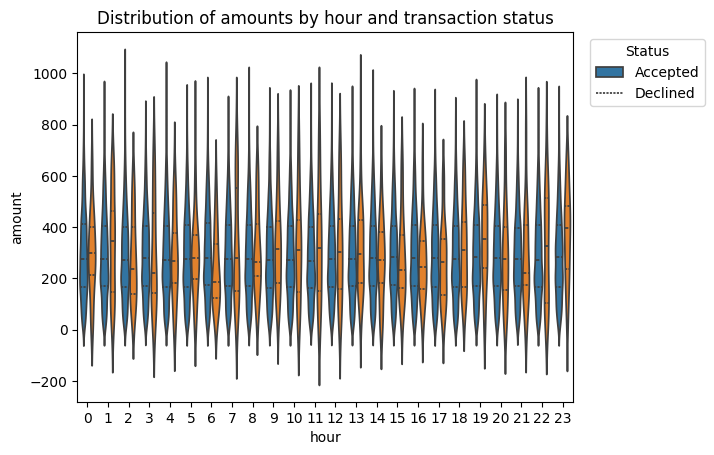

In [165]:
sns.violinplot(
    x="hour",       
    y="amount",
    hue="declined",  
    data=df_tr,
    inner="quart", 
    # split=True
)

plt.title("Distribution of amounts by hour and transaction status")
plt.legend(
    bbox_to_anchor=(1.02, 1),    
    title="Status",
    labels=["Accepted", "Declined"]
)
# añadir linea con plt grid
plt.show()

        Activa split per comparar acceptades i rebutjades i inner amb quartile per mostrar mediana i quartils.


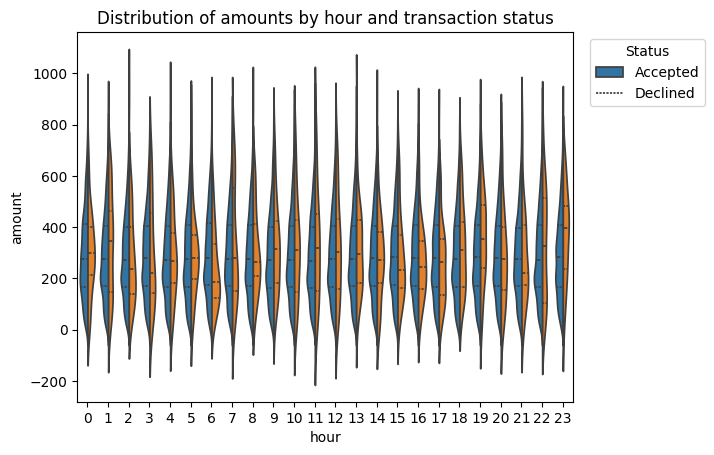

In [166]:
sns.violinplot(
    x="hour",       
    y="amount",
    hue="declined",  
    data=df_tr,
    inner="quart", 
    split=True
)

plt.title("Distribution of amounts by hour and transaction status")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    title="Status",
    labels=["Accepted", "Declined"]
)
plt.show()

- We will add a heatmap to get a clearer insight.

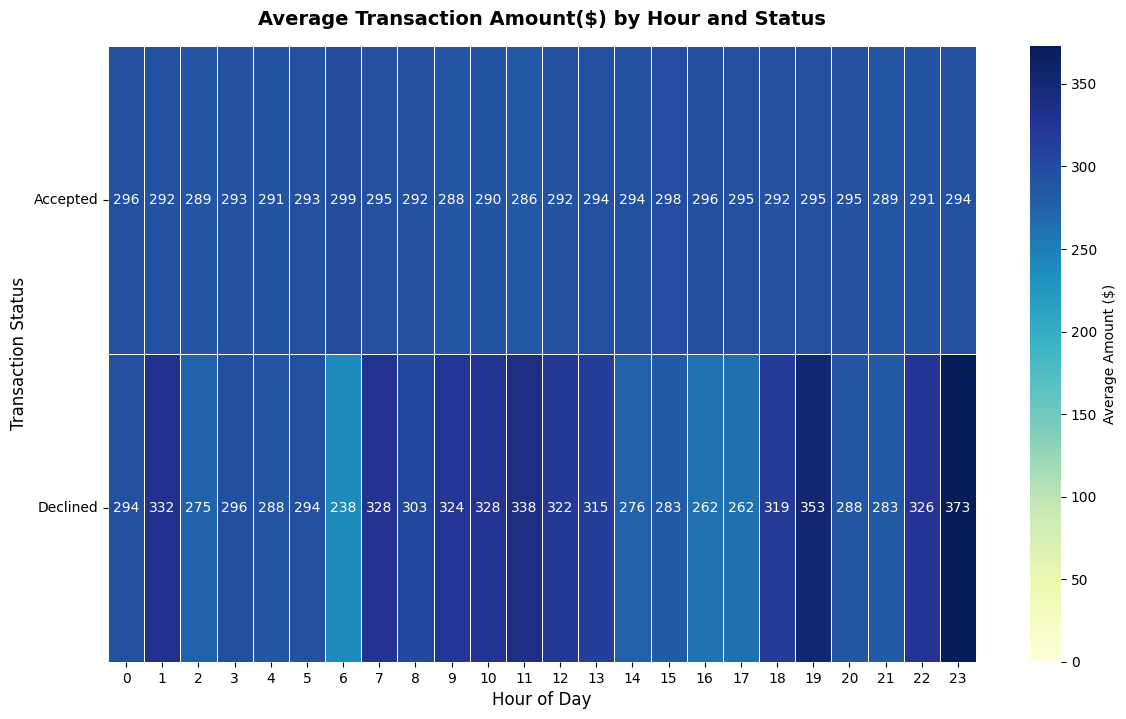

In [167]:

df_plot = df_tr.copy()
df_plot["Status"] = df_plot["declined"].map({0: "Accepted", 1: "Declined"})

heatmap_data = df_plot.pivot_table(
    index="Status",
    columns="hour",
    values="amount",
    aggfunc="mean"
)

plt.figure(figsize=(14, 8))
sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",  
    annot=True,  
    fmt=".0f",  
    linewidths=0.5,
    cbar_kws={"label": "Average Amount ($)"}, 
    vmin=0,
)

plt.title(
    "Average Transaction Amount($) by Hour and Status",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Transaction Status", fontsize=12)
plt.yticks(rotation=0) 

plt.show()


> Average transaction amounts are remarkably stable across all 24 hours, especially for accepted purchases, while declined transactions show noticeably higher hourly volatility and slightly higher peak averages.

    4. Quins dies de la setmana es concentra més activitat de venda?

    👉 Per a cada pregunta:

        Construeix una visualització senzilla en Python sense utilitzar IA.
        Interpreta breument el resultat obtingut.
        Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.



- My attempt: 
> sns.countplot: Directly counts how many records (rows) exist for each day.

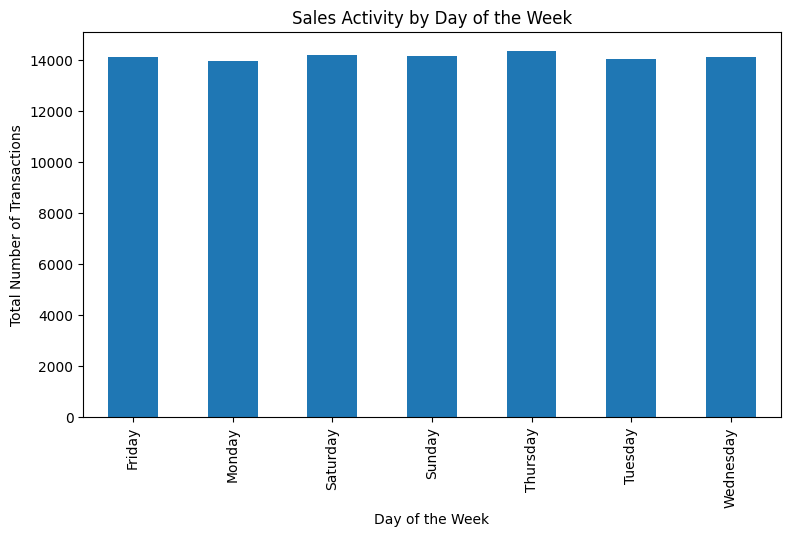

In [168]:
df_tr_accepted["day"] = df_tr_accepted["timestamp"].dt.day_name()

plt.figure(figsize=(9, 5))

df_tr_accepted.groupby("day")["amount"].count().plot(kind="bar", x="day", y="amount")

plt.title("Sales Activity by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Number of Transactions")
plt.show()




- AI attempt

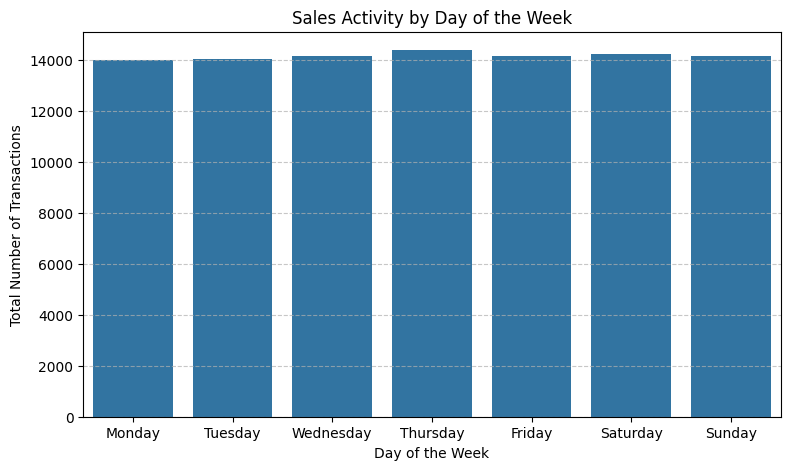

In [169]:
df_tr_accepted["day"] = df_tr_accepted["timestamp"].dt.day_name()

days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

group = (
    df_tr_accepted.groupby("day", observed=False)["id"]
    .count()
    .reset_index(name="total_transactions")
)

plt.figure(figsize=(9, 5))
sns.barplot(x="day", y="total_transactions", data=group, order=days_order)

plt.title("Sales Activity by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Number of Transactions")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


        Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.
> Both graphs indicate that the day with the highest number of sales is Thursday, but the one generated by the AI is much more readable since it sorts the days from Monday to Sunday and also adds dashed lines that help determine the transaction volume.

## Ex 2 Niv1: Preguntes analítiques complexes (amb guia)

    🌍 Context: Aquest exercici requereix combinar informació de diverses taules del model per poder respondre correctament les preguntes.

Aquí sí que serà necessari:

    » Fer merge entre taules.

    » Utilitzar groupby, pivot_table, crosstab...

    » Aplicar agregacions, transformacions intermèdies i funcions.


    Preguntes analítiques (amb guia general)


--- 
### Depenem excessivament d'un nombre reduït de països de companyies venedores?

Passos orientatius:

    1. Combinar la informació de transaccions amb la de companyies


- They are asking us to use merge. So, instead of doing an SQL JOIN query, we load the companies table separately and merge them using Python.


In [170]:
df_co = pd.read_sql("SELECT * FROM company", connection)

C:\Users\eduar\AppData\Local\Temp\ipykernel_4880\2133817695.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_co = pd.read_sql("SELECT * FROM company", connection)


- We inspect the columns in both DataFrames to determine the matching keys for the merge

In [171]:
# df_tr.info()
# df_co.info()

- We will merge the data using the company_id column from the transactions dataframe and the id column from the companies dataframe.
> We will use df_tr_accepted for this analysis. Since we are evaluating country dependence, we assume only completed transactions should be included, excluding any aborted or declined attempts.

In [172]:
df_merged = pd.merge(
    df_tr_accepted,
    df_co,
    left_on="business_id", # sprint2db
    # left_on="company_id",  # transactions db
    right_on="id",
    how="left"
)
# df_merged

    2. Agrupar la facturació per país.
    3. Calcular la facturació total generada per cada país.
    4. Ordenar els països de major a menor facturació.


> 🌍 Revenue Aggregation by Country. To evaluate geographic performance and market dependence, the transaction data is grouped by **`country`** to calculate the total revenue generated by each market. The results are then sorted in descending order to rank countries from highest to lowest billing volume. We also convert the amount to an integer as they are large amounts.


In [173]:
revenue_country = (
    df_merged.groupby("country")["amount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_country["amount"] = revenue_country["amount"].round().astype("Int64")


    5. Calcular el percentatge acumulat sobre el total.

In [174]:
revenue_total = revenue_country["amount"].sum()

revenue_total

29025210

In [175]:
revenue_country["percentage"] = (
    (revenue_country["amount"] / revenue_total) * 100).round(2)

revenue_country


,country,amount,percentage
0,Sweden,4884078,16.83
1,Netherlands,4470874,15.4
2,United Kingdom,4065098,14.01
3,Italy,4061061,13.99
4,Germany,3984664,13.73
5,France,1406668,4.85
6,United States,1085267,3.74
7,Belgium,937789,3.23
8,Norway,798332,2.75
9,Ireland,707379,2.44


    6. Visualitzar.



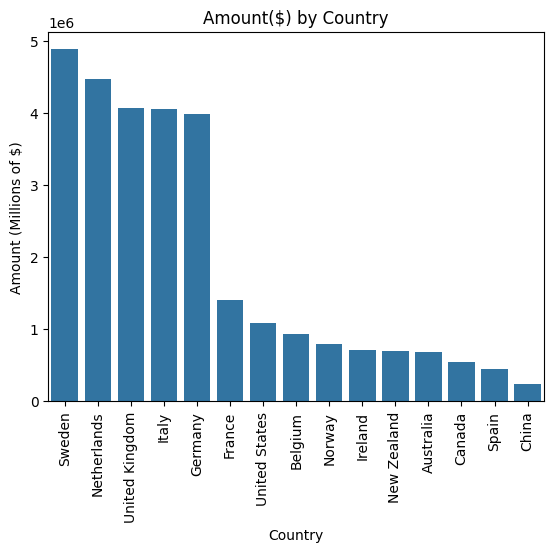

In [ ]:
sns.barplot(
    data=revenue_country,
    x="country",
    y="amount"
    )

plt.title("Amount($) by Country")
plt.xlabel("Country")
plt.ylabel("Amount (Millions of $)")
plt.xticks(rotation=90)
plt.show()


    Depenem excessivament d'un nombre reduït de països de companyies venedores?
> Yes. Five countries—Sweden, Netherlands, United Kingdom, Italy, and Germany—completely dominate the chart. Each of these individual markets generates around 4 to 5 million in transaction volume (amount).

---

### Is there seasonality in sales?

Guiding Steps

 1. Work with transaction dates.

 2. Extract the relevant temporal information (year and month).

- Create separate columns for the transaction year and month using the timestamp column.
- These variables will be used to identify temporal patterns and analyze seasonality.

 3. Calculate total sales volume (sum of `amount`) by year and month.

- Group transactions by year and month.
- Sum the values in the `amount` column for each year-month combination.
- This creates an aggregated table showing monthly sales revenue over time.

In [177]:
df_tr_accepted["month"] = df_tr_accepted["timestamp"].dt.month
df_tr_accepted["year"] = df_tr_accepted["timestamp"].dt.year

- We will group transactions by month and year, then calculates the total sales amount for each month-year combination. This creates a summarized table of monthly revenue over time.

- Then we will group all months together across different years and sums their sales. This allows us to identify seasonal patterns and determine which months tend to generate more revenue overall.



In [ ]:
monthly_sales_by_year = ( 
    df_tr_accepted.groupby(
        [df_tr_accepted["month"], df_tr_accepted["year"]] #!!!?????
        )["amount"]
    .sum()
    .reset_index()
)
# monthly_sales_by_year.head()

,month,year,amount
0,1,2015,221978.21
1,1,2016,224451.27
2,1,2017,222956.21
3,1,2018,227411.90
4,1,2019,222944.11


Sales by month and year sums the amount values for each month across all years,

In [ ]:

aggregated_monthly_sales = ( 
    monthly_sales_by_year.groupby(monthly_sales_by_year["month"])["amount"]
    .sum()
    .reset_index()
)
# aggregated_monthly_sales.head()


,month,amount
0,1,2274301.42
1,2,2493596.61
2,3,2520388.99
3,4,2442202.19
4,5,2502119.88


- For a better readibilty, we create a dictionary in order to show month names intead of month numbers. 
- Then mapping the month column (number) with the dictionary
- Finally we customizes the chart by adding a title, labeling the axes, and positioning the legend in the lower-left corner for better readability.




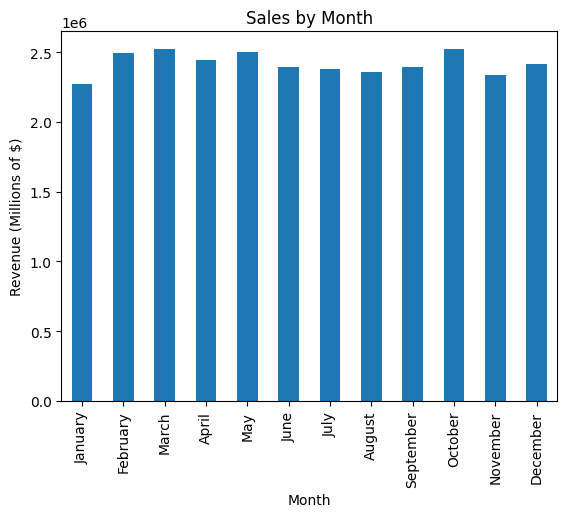

In [180]:
month_dict = {
    1: "January",2: "February",3: "March",4: "April",5: "May",
    6: "June",7: "July",8: "August",9: "September",10: "October",
    11: "November",12: "December"
}

aggregated_monthly_sales["month_name"] = aggregated_monthly_sales["month"].map(month_dict)

ax = aggregated_monthly_sales.plot(kind="bar", x="month_name", y="amount", legend=False)
ax.set_title("Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (Millions of $)")

plt.show()


> Revenue remains relatively stable throughout the year, ranging from approximately $2.3M to $2.5M per month. While March and October generate the highest revenues, January and November show the lowest performance. The limited variation across months suggests that sales are not strongly affected by seasonality and demand remains consistent throughout the year.

4. Compare temporal patterns across years. Create a pivot table.
- A pivot table is useful because it places years side by side, making patterns much easier to compare.

- Create a pivot table with months as rows and years as columns.
- Fill the table with total sales amounts.
- Use the resulting table to compare monthly sales patterns across different years and identify recurring seasonal trends.

In [181]:
pivot_table = monthly_sales_by_year.pivot_table(
    values="amount", 
    index="month", 
    columns="year"
)
pivot_table.head().style.format("{:,.0f}")

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
month,,,,,,,,,,
1,"221,978","224,451","222,956","227,412","222,944","231,703","243,340","224,710","228,414","226,394"
2,"245,780","248,112","252,304","245,092","259,807","248,318","257,434","235,428","251,423","249,898"
3,"253,001","246,634","237,621","237,100","276,818","258,873","250,861","271,978","241,711","245,792"
4,"245,597","240,833","251,597","234,246","242,708","244,252","259,771","237,165","241,264","244,769"
5,"248,585","241,307","240,126","244,449","242,550","253,700","239,662","276,263","261,355","254,123"


- Visualization

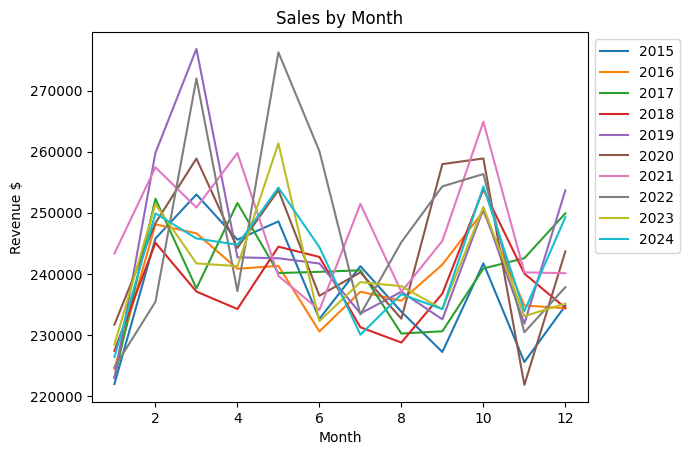

In [182]:
ax = pivot_table.plot(kind="line")
ax.set_title("Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue $")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")

plt.show()


> Consistent January & November Dips: Nearly every single year hits its lowest revenue points in Month 1 (January) and Month 11 (November), followed by a noticeable rebound in Month 12 (December)

---
EX 3 Nivell 1
---
### Concentration and Variability Analysis



Option A - Product Analysis (Only if you have the products table)

**Question:** Which products generate the most revenue and with what level of variability?

Guiding Steps


1. Combine transactions, the bridge table, and products.  
- Importing the products table and the bridge table so we can group the amount per product

In [183]:
# df_pr = pd.read_sql("SELECT * FROM product", connection) #transaction db
df_pr = pd.read_sql("SELECT * FROM products", connection) #sprint2db db
df_bridge_tr_pr = pd.read_sql("SELECT * FROM transaction_products", connection)


C:\Users\eduar\AppData\Local\Temp\ipykernel_4880\2174051936.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pr = pd.read_sql("SELECT * FROM products", connection) #sprint2db db
C:\Users\eduar\AppData\Local\Temp\ipykernel_4880\2174051936.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_bridge_tr_pr = pd.read_sql("SELECT * FROM transaction_products", connection)


Checking column names 


In [184]:
df_tr.columns


Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'year', 'hour'],
      dtype='object')

In [185]:
df_bridge_tr_pr.columns

Index(['transaction_id', 'product_id'], dtype='object')

In [186]:
df_pr.columns

Index(['id', 'product_name', 'priceDollars', 'colour', 'weight',
       'warehouse_id', 'category', 'brand', 'costDollars', 'launch_date'],
      dtype='object')

In [ ]:
# df_pr.head(3)

,id,product_name,priceDollars,colour,weight,warehouse_id,category,brand,costDollars,launch_date
0,1,Direwolf Stannis,161.11,#7c7c7c,1.0,WH-4,Sports,Runway Pro,63.84,2014-11-01
1,2,Tarly Stark,9.24,#919191,2.0,WH-3,Gaming,Questbyte,4.74,2013-02-07
2,3,duel tourney Lannister,171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,107.07,2013-08-18


- Merging transactions with bridge table in df_merged

In [188]:
df_merged = df_tr.merge(right=df_bridge_tr_pr, how="inner", left_on="id", right_on="transaction_id")

- Merging transactions+bridge with products in df_merged

In [189]:
df_merged = df_merged.merge(right=df_pr, how="inner", left_on="product_id", right_on="id")


In [ ]:
# df_merged.head(2)

,id_x,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,id_y,product_name,priceDollars,colour,weight,warehouse_id,category,brand,costDollars,launch_date
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,16,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30,11,16,81",2118,29.7573,-95.37960,...,16,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31


2. Calculate revenue per product using `groupby`, `sum`, and `sort`.


In [191]:
revenue_x_product = df_merged.groupby(["product_id", "product_name"])["priceDollars"].sum().astype(int).reset_index()
# revenue_x_product = df_merged.groupby(["product_name"])["priceDollars"].sum().astype(int).reset_index()

revenue_x_product = revenue_x_product.sort_values("priceDollars", ascending=False).reset_index(drop=True)

revenue_x_product = revenue_x_product.rename(
    columns={"priceDollars": "revenue"}
)

revenue_x_product.head(3)

,product_id,product_name,revenue
0,39,warden,505587
1,64,Direwolf,502352
2,67,Winterfell,500038


3. Select the top N products (e.g., top 10).


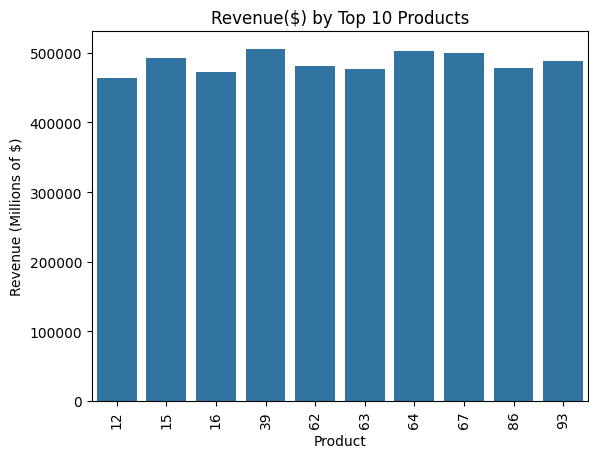

In [200]:
sns.barplot(
    data=revenue_x_product.head(10),
    x="product_id",
    y="revenue"
    )


plt.title("Revenue($) by Top 10 Products")
plt.xlabel("Product")
plt.ylabel("Revenue (Millions of $)")
plt.xticks(rotation=90)

plt.show()



4. Choose an appropriate visualization to analyze dispersion/variability.


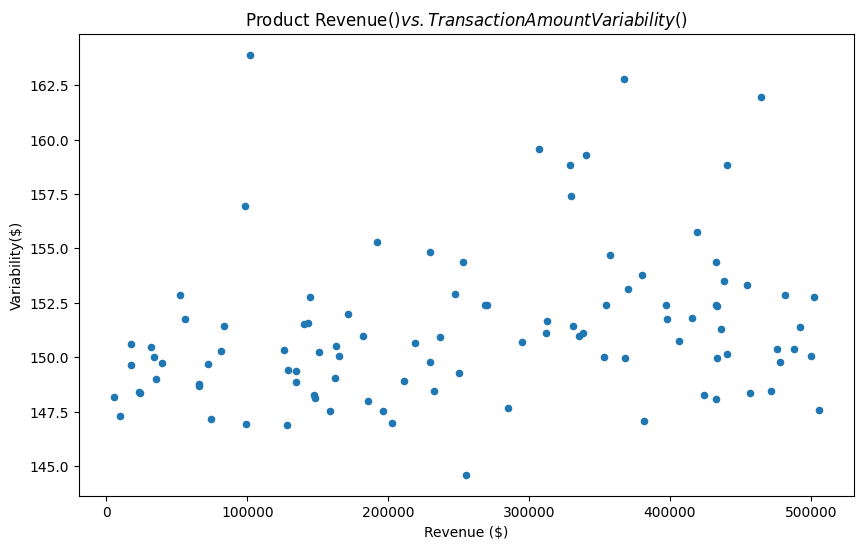

In [ ]:
product_stats = (
    df_merged.groupby("product_id")
    .agg(
        revenue=("priceDollars", "sum"),
        variability=("amount", "std")
    )
    .reset_index()
)

ax = product_stats.plot(
    kind="scatter",
    x="revenue",
    y="variability",
    figsize=(10, 6)
)

ax.set_title("Product Revenue($) vs. Transaction Amount Variability($)")
ax.set_xlabel("Revenue ($)")
ax.set_ylabel("Variability($)")

plt.show()

> After aggregating repeated product names, the scatter plot shows no strong relationship between product revenue and the variability of transaction amounts associated with each product. While some high-revenue products are linked to transactions with higher variability, the overall dispersion of points suggests that products generating more revenue do not consistently belong to more variable transactions.

---


### How Does Sales Activity Vary Across Time Slots Over the Years? (Hourly Patterns)

Guiding Steps


1. Create time slots based on the transaction hour. Use apply.


> We assume sales activity include both declined and accepted transactions. Hence, we use the transactions dataframe(df_tr).

In [195]:
def get_time_slot (hour):
    if 0 <= hour <= 5:
        return "Night"
    elif 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 17:
        return "Afternoon"
    else:
        return "Evening"

df_tr["time_slot"] = df_tr["hour"].apply(get_time_slot)
# df_merged["time_slot"] = df_tr["hour"].apply(get_time_slot)


2. Build an aggregated table using `pd.crosstab()`. It counts how many occurrences there are of each time slot in each year.


In [196]:
time_slot_crosstab = pd.crosstab(
    df_tr["time_slot"], 
    df_tr["year"]      
)

time_order = ['Morning', 'Afternoon', 'Evening', 'Night']

time_slot_crosstab = time_slot_crosstab.reindex(time_order)

time_slot_crosstab

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
time_slot,,,,,,,,,,
Morning,2461,2481,2476,2425,2554,2471,2584,2457,2551,2496
Afternoon,2457,2510,2554,2508,2544,2472,2593,2520,2464,2524
Evening,2500,2389,2441,2456,2450,2535,2532,2560,2454,2471
Night,2452,2474,2444,2523,2467,2615,2589,2569,2516,2460


3. Visualize the results with a heatmap.

- Define the correct chronological order
- Reindex the DataFrame (change 'index' to 'columns' if the time slots are columns)
- Plot the ordered heatmap


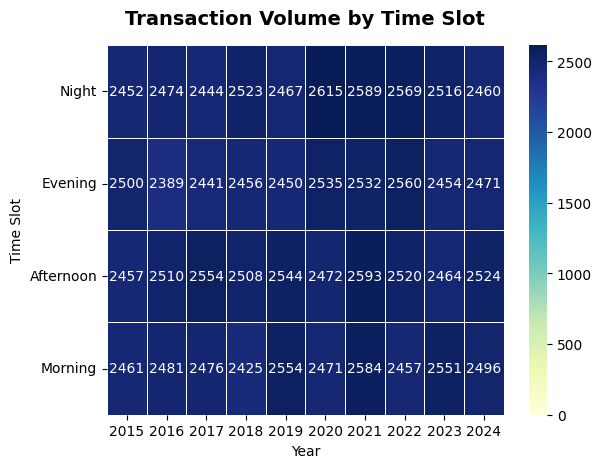

In [197]:
time_order = ['Morning', 'Afternoon', 'Evening', 'Night']

ordered_crosstab = time_slot_crosstab.reindex(time_order)

ax = sns.heatmap(
    ordered_crosstab,
    cmap='YlGnBu',      
    annot=True,          
    fmt='d',             
    linewidths=0.5,
    vmin=0      
)
ax.set_title('Transaction Volume by Time Slot', fontsize=14, pad=15, fontweight='bold')
ax.set_xlabel("Year")
ax.set_ylabel("Time Slot")
ax.invert_yaxis()
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.show()

> Transaction volume is completely flat and evenly distributed across every time of day and every year from 2015 to 2024, with every single cell hovering tightly around 6,000 to 6,600 transactions.

---
---

# TODO

# Nivell 2 – Anàlisi relacional i patrons avançats

## Exercici 1: Anàlisi de productes i captació d'usuaris

🎯 **Objectiu:** Analitzar el rendiment dels productes combinant ingressos, estabilitat i capacitat de captació de nous usuaris, amb l'objectiu de detectar possibles riscos de negoci associats a concentració excessiva d'ingressos, dependència d'usuaris recurrents i manca de creixement en base d'usuaris.

      **Pregunta clau:** Els productes que generen més ingressos també impulsen el creixement del negoci mitjançant la captació de nous usuaris, o bé el negoci depèn principalment d'usuaris recurrents comprant els mateixos productes?

### Passos orientatius:
1. Combina les taules necessàries.
2. Defineix un criteri de nou usuari si la transacció analitzada és la primera cronològicament que realitza al sistema (`es_nou_usuari = True / False`).
3. Agrega la informació per producte i calcula les mètriques següents:
   * Ingressos totals.
   * Nombre de nous usuaris.
   * Percentatge de nous usuaris sobre el total de compradors del producte.
4. Creació d'una tipologia analítica de productes a partir de les mètriques calculades, per exemple:
   * **Captador:** alta captació de nous usuaris.
   * **Recurrent:** ingressos elevats però baixa captació.
   * **Emergent:** baixa facturació però bona captació.
   * **Estancat:** baixos ingressos i baixa captació.
5. Construeix una visualització que permeti analitzar la relació entre les dimensions principals. Per exemple, un *scatter plot* amb:
   * **Eix X** $\rightarrow$ ingressos totals per producte.
   * **Eix Y** $\rightarrow$ nombre de nous usuaris.
   * **Color del punt** $\rightarrow$ tipologia analítica del producte.

📌 **Nota important:** No es tracta només de mostrar gràfics, sinó d'interpretar què implica per al negoci no captar nous usuaris.

---

## Exercici 2: Anàlisi geogràfica company–usuari i oportunitats d'expansió

🎯 **Objectiu:** Analitzar la relació entre el país de les companyies venedores, el país de residència dels usuaris i el flux de compra entre països.

   **Pregunta clau:** El negoci està basat en mercats locals (mateix país usuari–companyia) o hi ha una oportunitat real d'expansió internacional obrint més companyies en certs països?

### Passos orientatius:
1. Combina les taules necessàries.
2. Crea una variable clau d'anàlisi: `compra_local = True / False`.
3. Analitza el comportament global:
   * Percentatge de transaccions locals vs internacionals.
   * Percentatge de facturació local vs internacional.
4. Anàlisi per país de l'usuari (per cada país d'usuari):
   * `%` de compres a companyies del mateix país.
   * `%` de compres a companyies estrangeres.
   * Import total comprat.
5. Anàlisi per país de companyia (per cada país de companyia calcula quina part de la seva facturació ve de):
   * Usuaris locals.
   * Usuaris estrangers.
6. Escull una visualització que expliqui clarament el fenomen.
7. **Interpretació estratègica:**
   * En quins països valdria la pena obrir més companyies locals?
   * Hi ha països amb demanda però poca oferta local?
   * El negoci depèn massa de companyies d'un sol país?
   * Obrir companyies locals reduiria fricció o milloraria conversió?
